# Verify Dataset

## Step 1: Check dataset files

In [1]:
from pathlib import Path

DATA_ROOT = Path("../data/raw/ptb-xl")

required_files = [
    "ptbxl_database.csv",
    "scp_statements.csv",
    "records100",
    "records500",
]

print("Checking PTB-XL dataset...\n")

for item in required_files:
    path = DATA_ROOT / item

    if path.exists():
        print(f"[FOUND] {item}")
    else:
        print(f"[MISSING] {item}")

print("\nDataset location:", DATA_ROOT.resolve())

Checking PTB-XL dataset...

[FOUND] ptbxl_database.csv
[FOUND] scp_statements.csv
[FOUND] records100
[FOUND] records500

Dataset location: C:\Users\sintu\Desktop\Myocardial Infarction\data\raw\ptb-xl


## Step 2: Load metadata

In [2]:
import pandas as pd

metadata = pd.read_csv(
    DATA_ROOT / "ptbxl_database.csv",
    index_col="ecg_id"
)

scp_statements = pd.read_csv(
    DATA_ROOT / "scp_statements.csv",
    index_col=0
)

print("Metadata shape:", metadata.shape)
print("SCP statements shape:", scp_statements.shape)

print("\nMetadata columns:")
print(metadata.columns.tolist())

print("\nFirst 5 metadata records:")
display(metadata.head())

print("\nSCP statement columns:")
print(scp_statements.columns.tolist())

display(scp_statements.head())

Metadata shape: (21799, 27)
SCP statements shape: (71, 12)

Metadata columns:
['patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']

First 5 metadata records:


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
4,17014.0,24.0,0,NaN,82.0,2.0,0.0,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,...,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
5,17448.0,19.0,1,NaN,70.0,2.0,0.0,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,...,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr



SCP statement columns:
['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class', 'diagnostic_subclass', 'Statement Category', 'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code', 'DICOM Code']


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN
LNGQT,long QT-interval,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.0,NaN,NaN,NaN
NORM,normal ECG,1.0,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.0,NaN,NaN,F-000B7


## Step 3: Analyse the dataset

In [4]:
print("Total ECG recordings:", len(metadata))

print(
    "Unique patients:",
    metadata["patient_id"].nunique()
)

print("\nAge statistics:")
print(metadata["age"].describe())

print("\nSex distribution:")
print(metadata["sex"].value_counts(dropna=False))

print("\nStratified fold distribution:")
print(metadata["strat_fold"].value_counts().sort_index())

print("\nMissing values:")
print(metadata.isnull().sum())

Total ECG recordings: 21799
Unique patients: 18869

Age statistics:
count    21799.000000
mean        62.769301
std         32.308813
min          2.000000
25%         50.000000
50%         62.000000
75%         72.000000
max        300.000000
Name: age, dtype: float64

Sex distribution:
sex
0    11354
1    10445
Name: count, dtype: int64

Stratified fold distribution:
strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64

Missing values:
patient_id                          0
age                                 0
sex                                 0
height                          14825
weight                          12378
nurse                            1473
site                               17
device                              0
recording_date                      0
report                              0
scp_codes                           0
heart_axis                       8468
infarcti

## Step 4: Visualize patient demographics

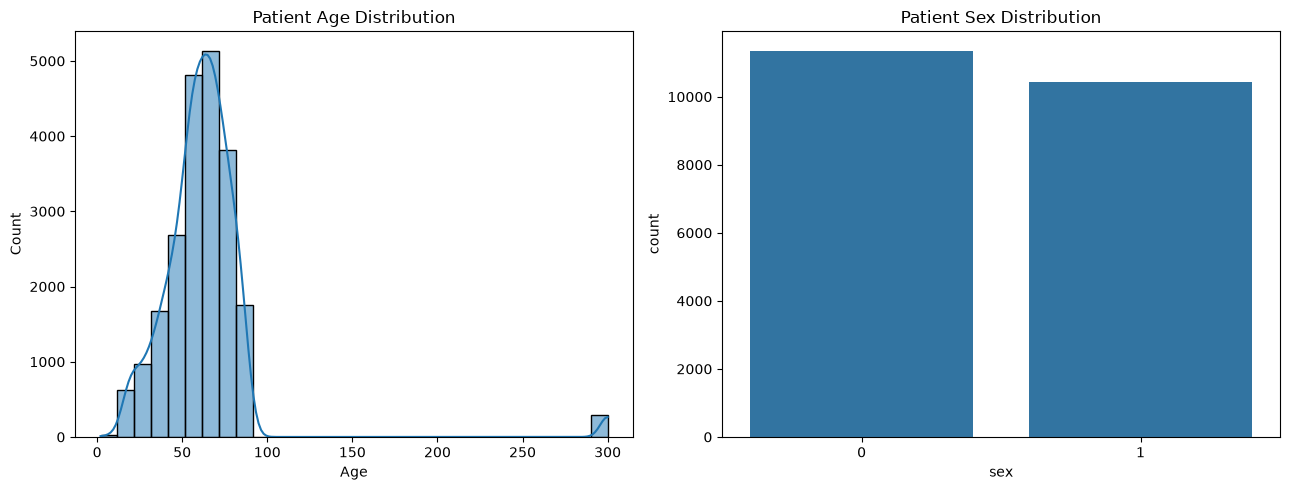

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    metadata["age"].dropna(),
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Patient Age Distribution")
axes[0].set_xlabel("Age")

sns.countplot(
    data=metadata,
    x="sex",
    ax=axes[1]
)

axes[1].set_title("Patient Sex Distribution")

plt.tight_layout()
plt.show()


## Step 5: Load an actual ECG recording

In [6]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

# Select the first ECG recording
ecg_row = metadata.iloc[0]

# Use the high-resolution recording
record_path = DATA_ROOT / ecg_row["filename_hr"]

signal, fields = wfdb.rdsamp(str(record_path))

print("Signal shape:", signal.shape)
print("Sampling frequency:", fields["fs"])
print("Signal units:", fields["units"])
print("Signal names:", fields["sig_name"])

print("Patient ID:", ecg_row["patient_id"])
print("ECG ID:", metadata.index[0])

Signal shape: (5000, 12)
Sampling frequency: 500
Signal units: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']
Signal names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Patient ID: 15709.0
ECG ID: 1


## Step 6: Visualize the ECG signal

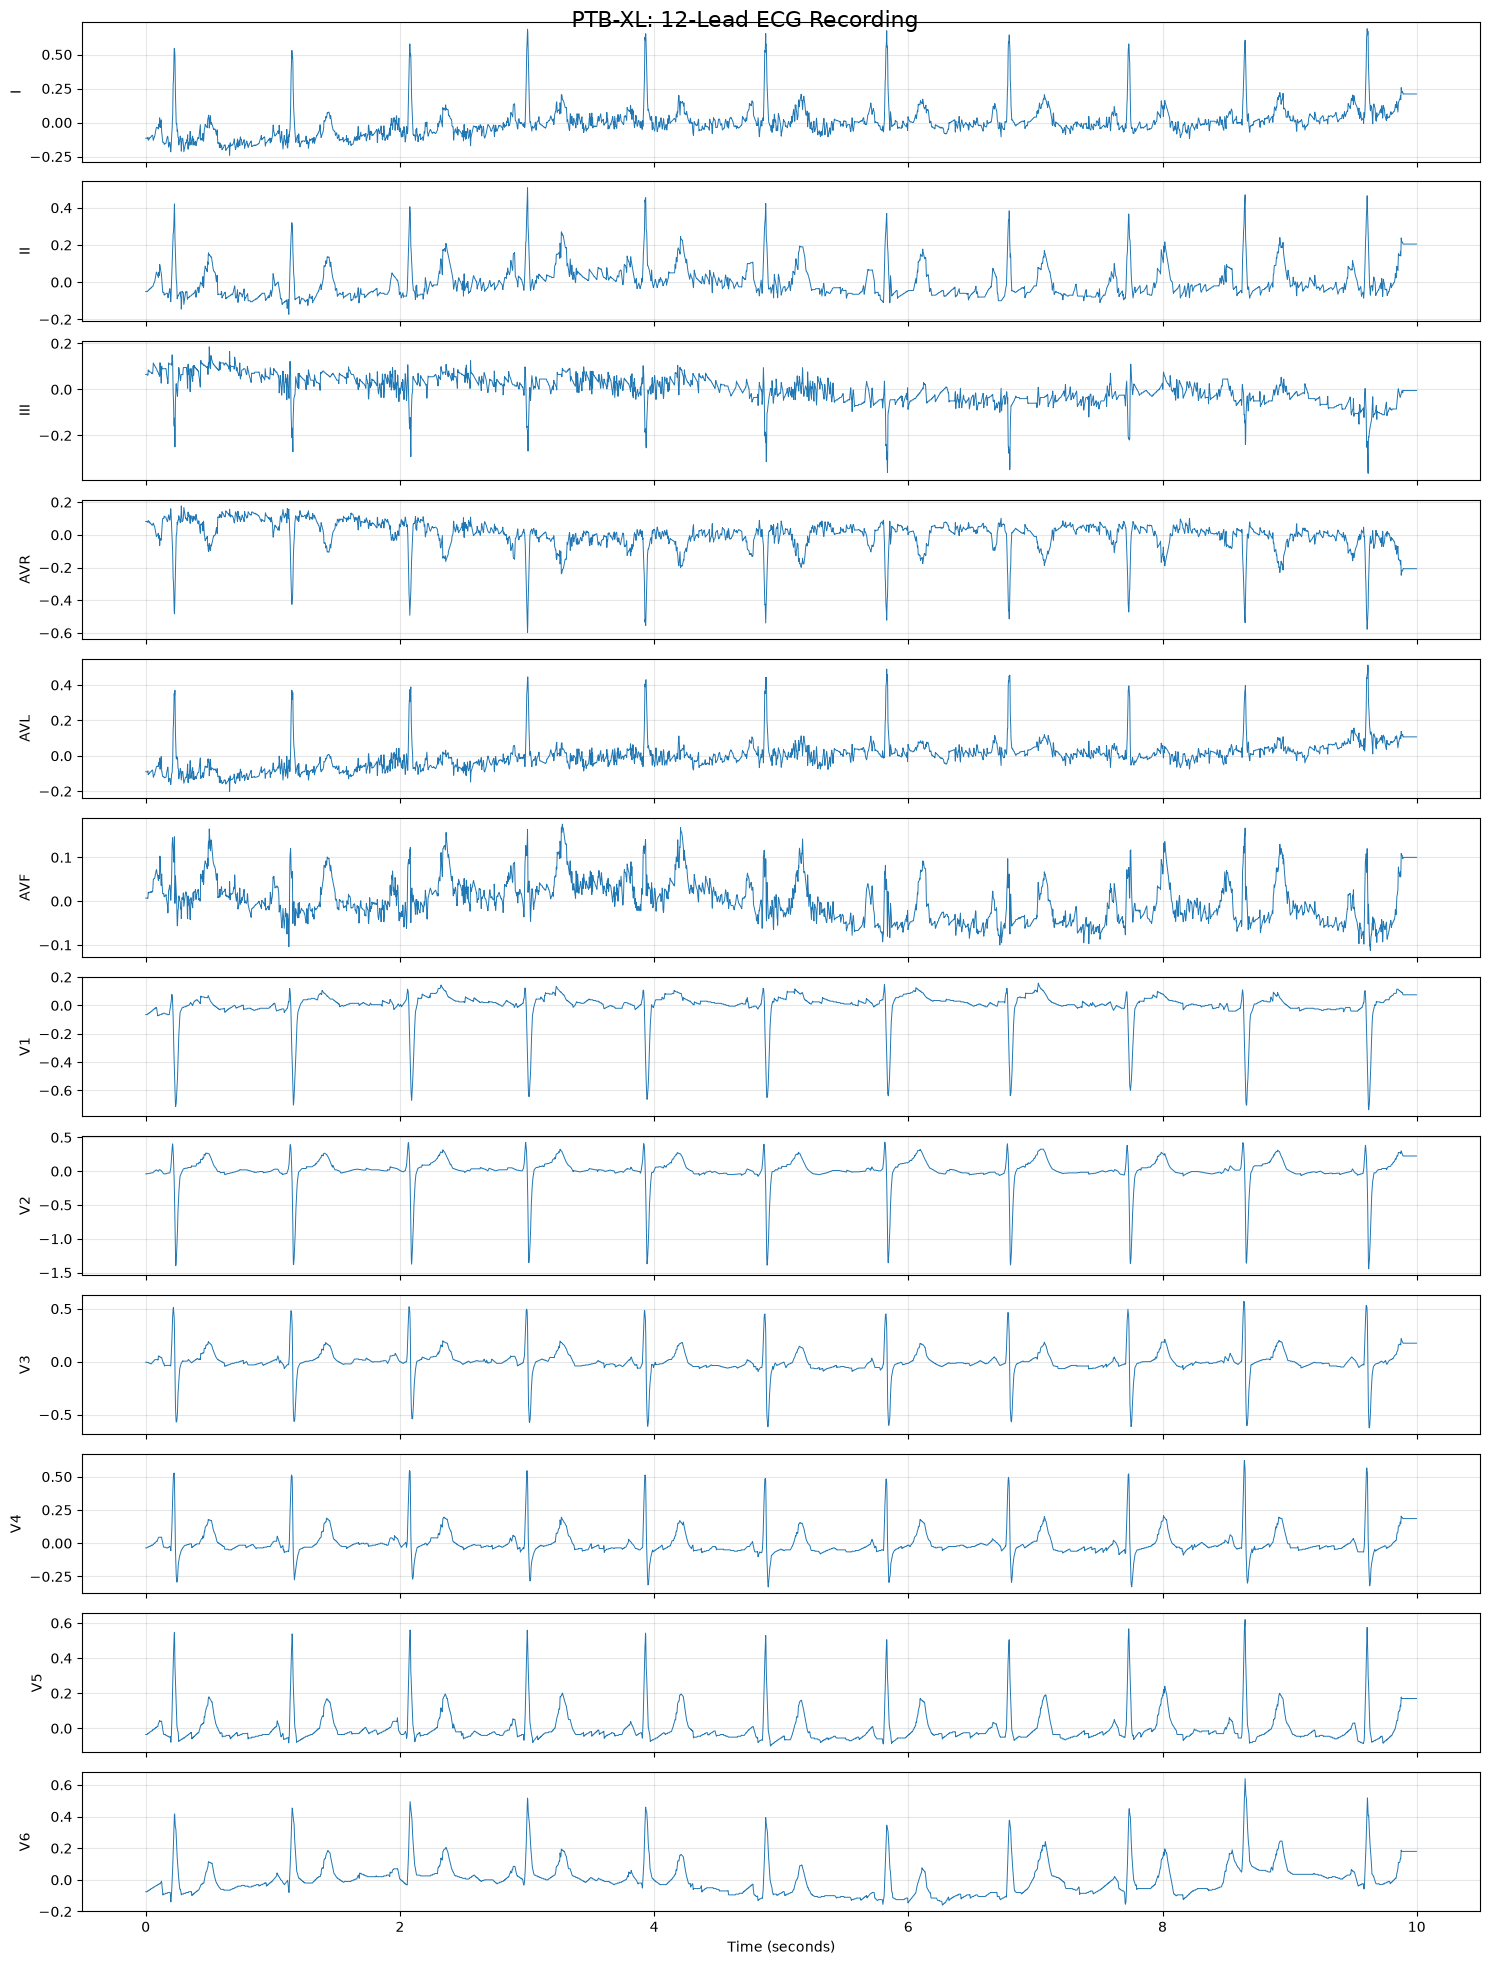

In [7]:
sampling_rate = int(fields["fs"])

time = np.arange(signal.shape[0]) / sampling_rate

fig, axes = plt.subplots(
    12, 1,
    figsize=(15, 20),
    sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(time, signal[:, i], linewidth=0.7)
    ax.set_ylabel(fields["sig_name"][i])
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")

plt.suptitle(
    "PTB-XL: 12-Lead ECG Recording",
    fontsize=16
)

plt.tight_layout()
plt.show()

## Step 7: Integrity check

In [10]:
from pathlib import Path

import pandas as pd

DATA_ROOT = Path("../data/raw/ptb-xl")

metadata = pd.read_csv(
    DATA_ROOT / "ptbxl_database.csv",
    index_col="ecg_id"
)

print("Total metadata records:", len(metadata))
print("Unique ECG IDs:", metadata.index.nunique())
print("Unique patients:", metadata["patient_id"].nunique())

print("\nDuplicate ECG IDs:", metadata.index.duplicated().sum())

for column in ["filename_lr", "filename_hr"]:
    missing_files = [
        filename
        for filename in metadata[column].dropna()
        if not (DATA_ROOT / filename).with_suffix(".hea").exists()
    ]

    print(f"\n{column}")
    print("Missing header files:", len(missing_files))
    print("Examples:", missing_files[:5])

print("\nOfficial fold distribution:")
print(metadata["strat_fold"].value_counts().sort_index())

Total metadata records: 21799
Unique ECG IDs: 21799
Unique patients: 18869

Duplicate ECG IDs: 0

filename_lr
Missing header files: 0
Examples: []

filename_hr
Missing header files: 0
Examples: []

Official fold distribution:
strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64
